# WeLoveReviews: sentiment analysis of 500 customer reviews

**Business question.** Does written sentiment support the 4.5/5 average rating, and where does the model make operationally important mistakes?

This notebook is the reproducible analysis artifact. Inference is implemented in `src/app.py`; it loads the pinned multilingual star-rating model once, predicts all 500 reviews in batches, and saves the processed dataset used below.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "requirements.txt").exists())
RAW = ROOT / "data/raw/reviews.csv"
PROCESSED = ROOT / "data/processed/reviews_with_sentiment.csv"
raw = pd.read_csv(RAW)
df = pd.read_csv(PROCESSED)
print(f"Raw rows: {len(raw):,}; processed rows: {len(df):,}")
print("Columns:", list(df.columns))

Raw rows: 500; processed rows: 500
Columns: ['review_id', 'rating', 'review_text', 'predicted_stars', 'confidence', 'sentiment']


## Data quality and preparation

The analysis keeps the supplied reviews intact. The production script validates required columns, rejects blank review text and ratings outside 1–5, then adds only model outputs. Missingness and duplicate IDs are checked below.

In [2]:
quality = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "dtype": df.dtypes.astype(str),
})
display(quality)
print("Duplicate review IDs:", int(df["review_id"].duplicated().sum()))
print("Average human rating:", round(df["rating"].mean(), 2))
display(df["rating"].value_counts().sort_index().rename("reviews").to_frame())

,missing_values,dtype
review_id,0,int64
rating,0,int64
review_text,0,object
predicted_stars,0,int64
confidence,0,float64
sentiment,0,object


Duplicate review IDs: 0
Average human rating: 4.5


,reviews
rating,
1,12
2,18
3,38
4,72
5,360


## Model and mapping

The classifier is `nlptown/bert-base-multilingual-uncased-sentiment`, pinned in `src/app.py` to revision `8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d`. It directly predicts 1–5 stars, which makes the rubric mapping explicit: **1–2 = Negative, 3 = Neutral, 4–5 = Positive**. The model was loaded once and reused for batched inference; model weights are not committed.

,count,percentage
sentiment,,
Positive,412,82.4
Neutral,41,8.2
Negative,47,9.4


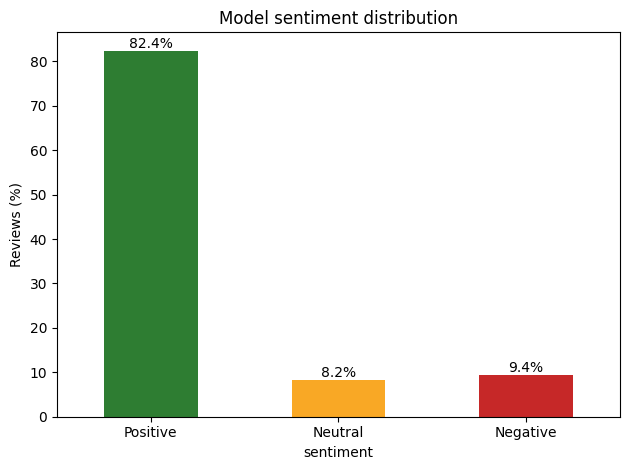

In [3]:
summary = (df["sentiment"].value_counts()
           .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
           .rename("count").to_frame())
summary["percentage"] = (summary["count"] / len(df) * 100).round(1)
display(summary)
ax = summary["percentage"].plot.bar(color=["#2e7d32", "#f9a825", "#c62828"], ylabel="Reviews (%)", title="Model sentiment distribution")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Does sentiment agree with the 4.5 rating?

Yes, directionally. The human average is **4.50/5**, while the model marks **82.4%** of reviews positive. A 4.5 average does not imply every review is positive, so the 8.2% neutral and 9.4% negative shares are plausible. The comparison also reveals model disagreement worth auditing rather than treating predictions as ground truth.

In [4]:
agreement = (df["rating"] == df["predicted_stars"]).mean()
within_one = ((df["rating"] - df["predicted_stars"]).abs() <= 1).mean()
print(f"Exact star agreement: {agreement:.1%}")
print(f"Within one star: {within_one:.1%}")
cross = pd.crosstab(df["rating"], df["sentiment"], margins=True)
display(cross)

Exact star agreement: 85.8%
Within one star: 96.6%


sentiment,Negative,Neutral,Positive,All
rating,,,,
1,12,0,0,12
2,16,2,0,18
3,3,35,0,38
4,1,3,68,72
5,15,1,344,360
All,47,41,412,500


## False negatives

For this assignment, a false negative is a human rating of 4–5 with a model prediction of 1–2. These errors matter because an automated alerting workflow could escalate satisfied customers or distort the business's reputation signal.

In [5]:
false_negatives = df[(df["rating"] >= 4) & (df["predicted_stars"] <= 2)].copy()
print(f"False negatives: {len(false_negatives)} ({len(false_negatives)/len(df):.1%} of all reviews)")
display(false_negatives[["review_id", "rating", "predicted_stars", "confidence", "review_text"]].head(10))

False negatives: 16 (3.2% of all reviews)


,review_id,rating,predicted_stars,confidence,review_text
13,14,4,1,0.444348,Tried Harbor House Café after seeing it recomm...
14,15,5,1,0.389344,Every dish was bursting with flavor. The place...
72,73,5,1,0.267875,Stopped by Harbor House Café for the first tim...
86,87,5,1,0.324705,Tried Harbor House Café after seeing it recomm...
137,138,5,2,0.275116,Tried Harbor House Café after seeing it recomm...
199,200,5,2,0.368520,Stopped by Harbor House Café for the first tim...
203,204,5,1,0.349168,Came to Harbor House Café for a birthday brunc...
253,254,5,1,0.364092,Stopped by Harbor House Café for the first tim...
269,270,5,1,0.409076,Stopped by Harbor House Café for the first tim...
321,322,5,1,0.607707,Every dish was bursting with flavor. The staff...


The false negatives frequently contain **implicit praise**, hospitality phrases, or mixed clauses (for example, a complaint followed by “the food made up for it”). The star classifier appears sensitive to isolated negative wording and sometimes misreads restaurant-specific idioms such as “bursting with flavor.” This is a testable error hypothesis, not proof: a larger labeled audit would be needed before changing production policy.

## Manual review sample (20 reviews)

The sample combines 12 deterministic random reviews with 8 false negatives so that routine predictions and the highest-risk disagreement class are both reviewed. Notes are based on the human rating and model output; no review text is sent to another service.

In [6]:
routine = df.drop(index=false_negatives.index).sample(12, random_state=42)
risk = false_negatives.head(8)
manual = pd.concat([routine, risk]).copy()
manual["human_check"] = manual.apply(
    lambda r: "Aligned/near-aligned with human rating" if abs(r.rating-r.predicted_stars) <= 1
    else "Material disagreement — inspect mixed wording or implicit praise", axis=1
)
manual["review_excerpt"] = manual["review_text"].str.slice(0, 110)
display(manual[["review_id", "rating", "predicted_stars", "sentiment", "review_excerpt", "human_check"]].reset_index(drop=True))

,review_id,rating,predicted_stars,sentiment,review_excerpt,human_check
0,431,5,5,Positive,Tried Harbor House Café after seeing it recomm...,Aligned/near-aligned with human rating
1,491,2,2,Negative,Visited Harbor House Café last weekend. My egg...,Aligned/near-aligned with human rating
2,187,5,5,Positive,Grabbed a quick coffee at Harbor House Café th...,Aligned/near-aligned with human rating
3,460,5,5,Positive,Regular customer at Harbor House Café here. Th...,Aligned/near-aligned with human rating
4,307,5,5,Positive,Stopped by Harbor House Café for the first tim...,Aligned/near-aligned with human rating
5,154,5,5,Positive,Visited Harbor House Café last weekend. The pl...,Aligned/near-aligned with human rating
6,392,5,5,Positive,Stopped by Harbor House Café for the first tim...,Aligned/near-aligned with human rating
7,398,5,5,Positive,Regular customer at Harbor House Café here. Th...,Aligned/near-aligned with human rating
8,496,5,4,Positive,Tried Harbor House Café after seeing it recomm...,Aligned/near-aligned with human rating
9,235,4,4,Positive,Came to Harbor House Café for a birthday brunc...,Aligned/near-aligned with human rating


## Conclusion and recommendation

The model's 82.4% positive share broadly supports the strong 4.5/5 rating, but the 16 false negatives show why sentiment should support—not replace—human judgment. WeLoveReviews can use the classifier for triage and aggregate monitoring, with low-confidence results and high-rating/negative-prediction conflicts routed to manual review. Before production use, track false-negative rate on a larger labeled sample and test domain-adapted alternatives against this pinned baseline.